In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("./output/csv/Catalogo_sismico_limpio.csv")

In [3]:
df.head()

,id,fecha_utc,hora_utc,latitud,longitud,profundidad,magnitud,fecha_hora_utc,year,month,day,monht_name,day_name,clasificacion
0,0,1960-01-13,15:40:34,-16.145,-72.144,60,7.5,1960-01-13 15:40:34,1960,1,13,January,Wednesday,Mayor
1,1,1960-01-15,09:30:24,-15.000,-75.000,70,7.0,1960-01-15 09:30:24,1960,1,15,January,Friday,Mayor
2,2,1960-01-17,02:57:58,-14.500,-74.500,150,6.4,1960-01-17 02:57:58,1960,1,17,January,Sunday,Fuerte
3,3,1960-01-23,03:37:32,-12.500,-68.500,300,5.8,1960-01-23 03:37:32,1960,1,23,January,Saturday,Moredaro
4,4,1960-01-30,05:07:24,-5.500,-77.500,100,5.7,1960-01-30 05:07:24,1960,1,30,January,Saturday,Moredaro


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23672 entries, 0 to 23671
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              23672 non-null  int64  
 1   fecha_utc       23672 non-null  str    
 2   hora_utc        23672 non-null  str    
 3   latitud         23672 non-null  float64
 4   longitud        23672 non-null  float64
 5   profundidad     23672 non-null  int64  
 6   magnitud        23672 non-null  float64
 7   fecha_hora_utc  23672 non-null  str    
 8   year            23672 non-null  int64  
 9   month           23672 non-null  int64  
 10  day             23672 non-null  int64  
 11  monht_name      23672 non-null  str    
 12  day_name        23672 non-null  str    
 13  clasificacion   23672 non-null  str    
dtypes: float64(3), int64(5), str(6)
memory usage: 2.5 MB


In [13]:
# config del estilo general
sns.set_theme(style='whitegrid')

# parámetros de medidas 
plt.rcParams['figure.figsize'] =  (10, 5)  # 1000 x 500, dpi=100
plt.rcParams['font.size'] = 11 

In [14]:
meses_ordenados = [
    "enero", "febrero", "marzo", "abril",
    "mayo", "junio", "julio", "agosto",
    "septiembre", "octubre", "noviembre", "diciembre"
]

Años con más sismos

In [9]:
# agrupar (groupby)
simos_year = df.groupby('year').size()
simos_year.tail(10)

year
2014    1025
2015     814
2016     946
2017     780
2018     543
2019     565
2020     808
2021     834
2022     497
2023     463
dtype: int64

In [16]:
simos_year.index

Index([1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983,
       1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995,
       1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007,
       2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019,
       2020, 2021, 2022, 2023],
      dtype='int64', name='year')

In [18]:
simos_year = df.groupby('year').size().reset_index(name='total_sismos')
simos_year

,year,total_sismos
0,1960,26
1,1961,29
2,1962,22
3,1963,85
4,1964,94
...,...,...
59,2019,565
60,2020,808
61,2021,834
62,2022,497


In [19]:
simos_year_sort_desc = simos_year.sort_values(by=['total_sismos'], ascending=False)
simos_year_sort_desc.head()

,year,total_sismos
54,2014,1025
51,2011,1022
53,2013,991
56,2016,946
61,2021,834


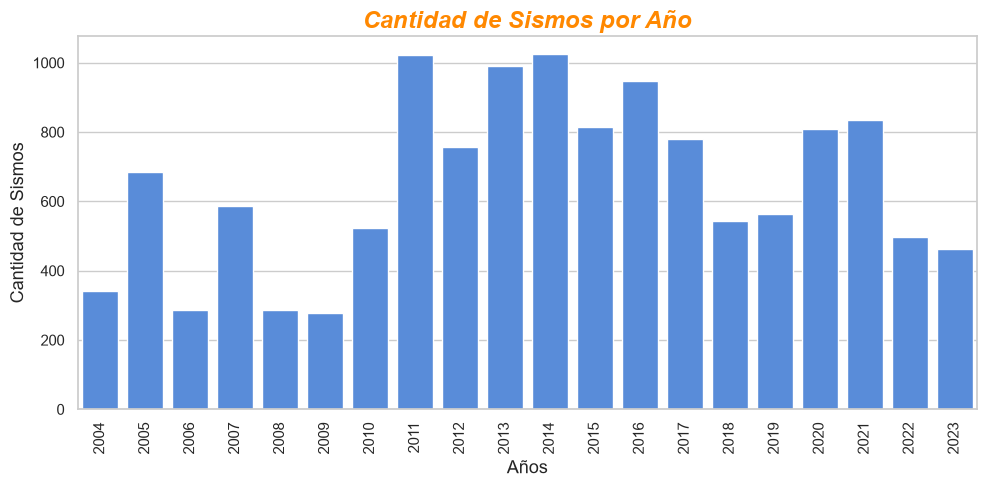

In [57]:
plt.Figure(figsize=(16,7)) # crear una hoja de 1400 x 500 

sns.barplot(data=simos_year.tail(20), x='year', y='total_sismos', color='#48e') # grafica de barras

plt.title("Cantidad de Sismos por Año", fontsize=17, color="#f80", fontweight='700', fontstyle='italic')
plt.xlabel("Años", fontsize=13)
plt.ylabel("Cantidad de Sismos", fontsize=13)
# plt.grid(False) $
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

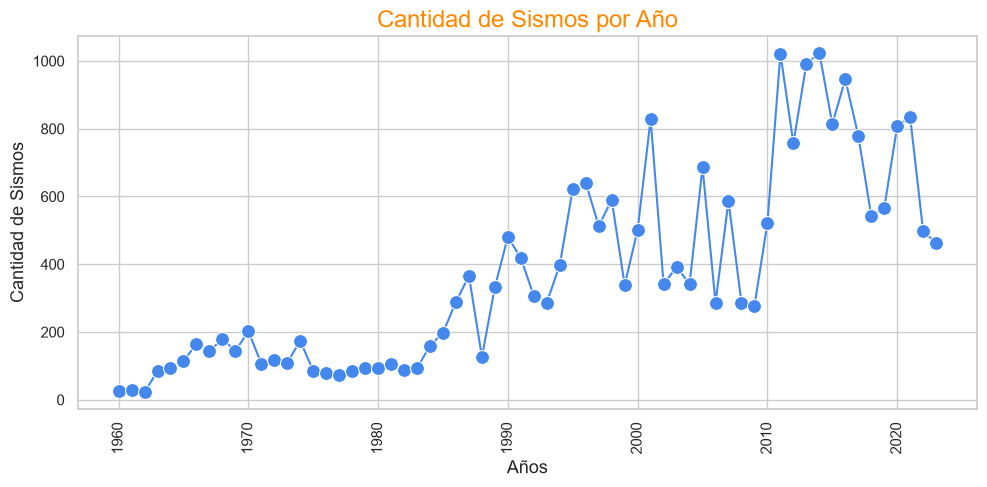

In [62]:
plt.Figure(figsize=(20,8)) # crear una hoja de 1400 x 500 

sns.lineplot(data=simos_year, x='year', y='total_sismos', color='#48e', marker='o', markersize=10) # grafica de barras

plt.title("Cantidad de Sismos por Año", fontsize=17, color="#f80")
plt.xlabel("Años", fontsize=13)
plt.ylabel("Cantidad de Sismos", fontsize=13)
# plt.grid(False) $
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

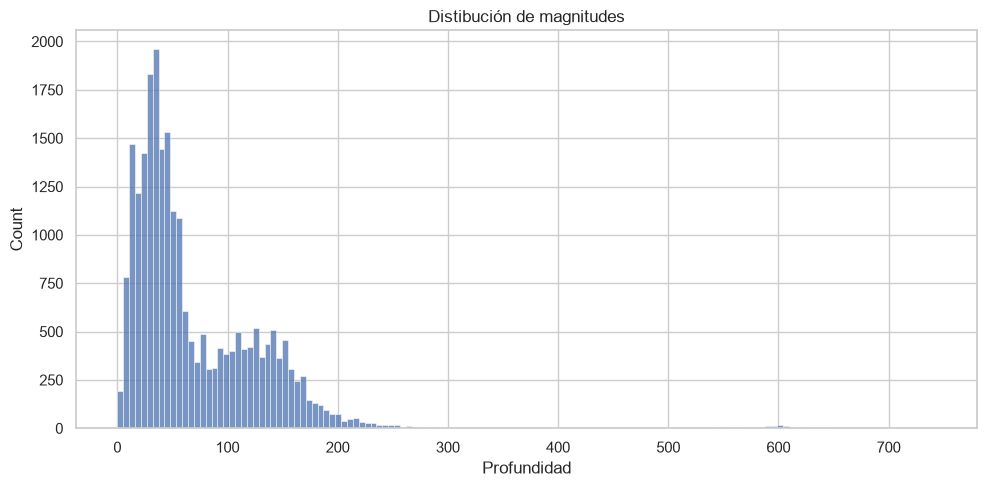

In [68]:
sns.histplot(data=df, x="profundidad")
plt.title("Distibución de magnitudes")
plt.xlabel("Profundidad")
plt.tight_layout()

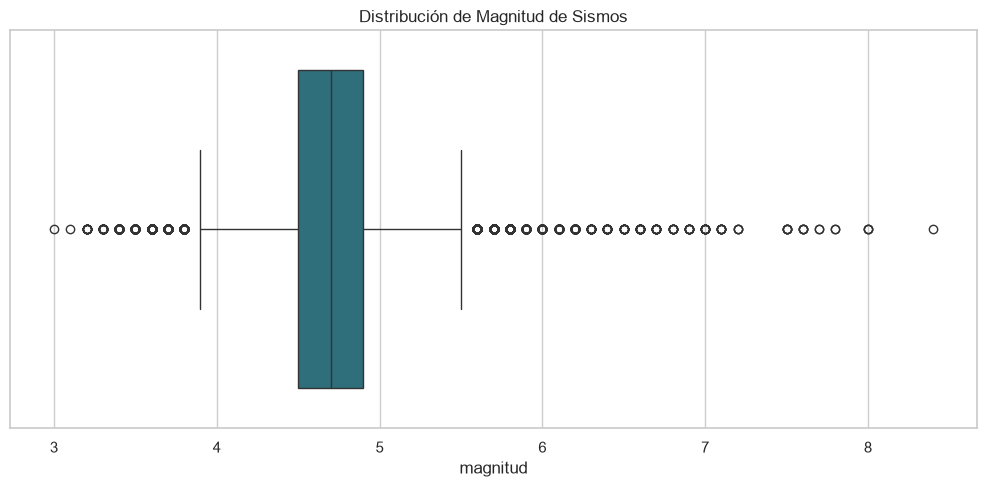

In [ ]:
sns.boxplot(data=df, x='magnitud', color="#278")
plt.title("Distribución de Magnitud de Sismos")
plt.tight_layout()

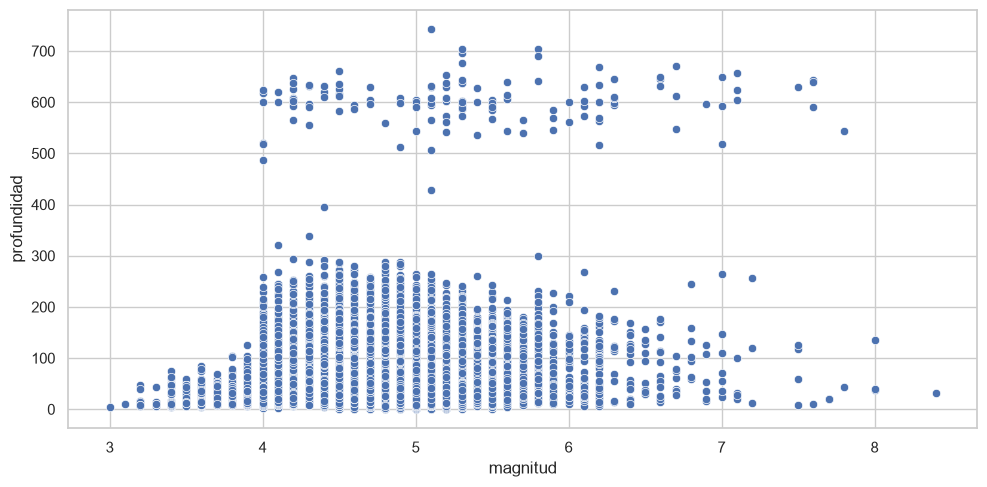

In [ ]:
# grafico de dispersión
sns.scatterplot(data=df, x="magnitud", y="profundidad")
plt.tight_layout()

In [78]:
# mapa de calor
tabla_meses = df.pivot_table(
    index='month', 
    columns='year',
    values='id',
    aggfunc='count',
    observed=False
)

In [84]:
tabla_meses

year,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
month,,,,,,,,,,,,,,,,,,,,,
1,5.0,2.0,2.0,4.0,7.0,13.0,11.0,7.0,11.0,11.0,...,67.0,80.0,120.0,93.0,57.0,50.0,73.0,51.0,57.0,32.0
2,2.0,1.0,NaN,4.0,13.0,4.0,10.0,11.0,6.0,14.0,...,87.0,84.0,69.0,63.0,38.0,45.0,67.0,52.0,24.0,30.0
3,1.0,1.0,4.0,5.0,9.0,7.0,8.0,9.0,8.0,13.0,...,114.0,101.0,87.0,74.0,42.0,42.0,68.0,66.0,41.0,49.0
4,1.0,2.0,1.0,6.0,11.0,7.0,4.0,12.0,10.0,8.0,...,79.0,60.0,58.0,80.0,48.0,46.0,90.0,70.0,30.0,23.0
5,2.0,NaN,NaN,4.0,8.0,9.0,14.0,9.0,8.0,7.0,...,99.0,58.0,89.0,69.0,54.0,77.0,99.0,87.0,34.0,38.0
6,NaN,2.0,NaN,7.0,8.0,12.0,24.0,16.0,67.0,12.0,...,81.0,57.0,68.0,76.0,38.0,49.0,49.0,62.0,47.0,45.0
7,4.0,4.0,3.0,5.0,6.0,13.0,9.0,15.0,19.0,15.0,...,72.0,53.0,56.0,62.0,38.0,50.0,51.0,68.0,35.0,41.0
8,NaN,8.0,2.0,9.0,6.0,8.0,12.0,17.0,10.0,15.0,...,109.0,44.0,71.0,69.0,34.0,41.0,60.0,76.0,34.0,48.0
9,4.0,2.0,5.0,5.0,6.0,11.0,12.0,12.0,11.0,9.0,...,58.0,59.0,75.0,60.0,52.0,36.0,48.0,77.0,31.0,33.0


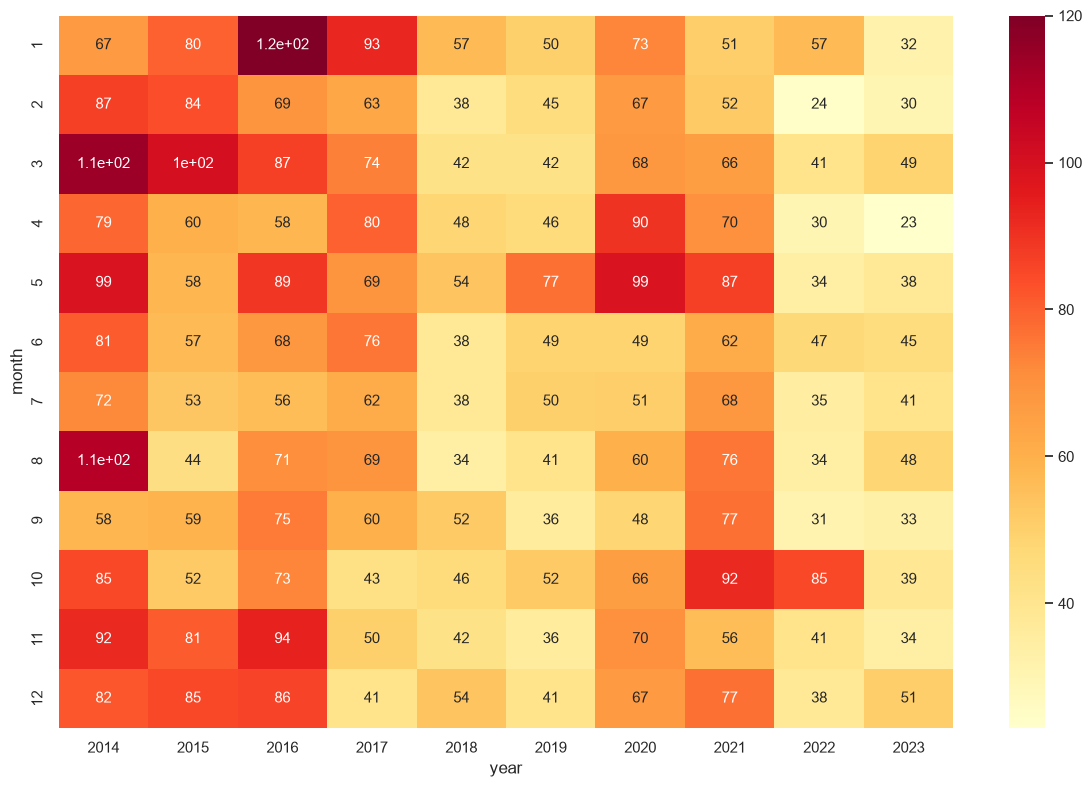

In [83]:
plt.figure(figsize=(12,8))
sns.heatmap(tabla_meses.iloc[:, -10:], cmap='YlOrRd', annot=True)
plt.tight_layout()

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [8]:
datos = [14,12,15,17,19,20,22,45,24]
datos.sort()
datos

[12, 14, 15, 17, 19, 20, 22, 24, 45]

In [9]:
q1,q3 = np.percentile(datos, [25,75])
iqr = q3 - q1 
lim_sup = q3 + (1.5 * iqr) 
lim_inf = q1 - (1.5 * iqr) 

print(f"Percentil 25: {q1}\nPercentil 75: {q3}\nRnago Intercualtilico: {iqr}\nLímite inferior: {lim_inf}\nLímite superior: {lim_sup}")

Percentil 25: 15.0
Percentil 75: 22.0
Rnago Intercualtilico: 7.0
Límite inferior: 4.5
Límite superior: 32.5


In [10]:
# Gráfica: 
# config del estilo general
sns.set_theme(style='whitegrid')

# parámetros de medidas 
plt.rcParams['figure.figsize'] =  (10, 5)  # 1000 x 500, dpi=100
plt.rcParams['font.size'] = 11 

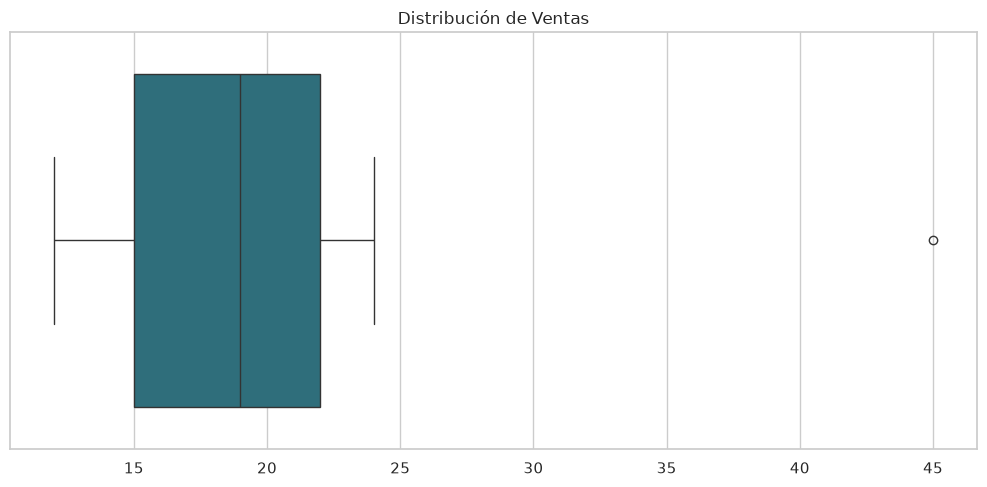

In [12]:
sns.boxplot(x=datos, color="#278")
plt.title("Distribución de Ventas")
plt.tight_layout()